# EC estimation with a precision-based reference
This notebook estimates EC for one participant and chooses a representative decay timescale from the minimum correlation with the precision-based reference. It also checks how similar the EC patterns remain across the convergent range.

## 1. Set the participant and input files
Choose the subject, run and tau grid below. The example uses the local pyMOU source and the existing 100-to-62 mapping. Keep the same preprocessing when comparing or reusing fits.

In [12]:
import os
os.listdir(Path.home() / "hcp_parcellated")

['100206',
 '100307',
 '100408',
 '100610',
 '101006',
 '101107',
 '101309',
 '101410',
 '101915',
 '102008',
 '102109',
 '102311',
 '102513',
 '102614',
 '102715',
 '102816',
 '103010',
 '103111',
 '103212',
 '103414',
 '103515',
 '103818',
 '104012',
 '104416',
 '104820',
 '105014',
 '105115',
 '105216',
 '105620',
 '105923',
 '106016',
 '106319',
 '106521',
 '106824',
 '107018',
 '107220',
 '107321',
 '107422',
 '107725',
 '108020',
 '108121',
 '108222',
 '108323',
 '108525',
 '108828',
 '109123',
 '109325',
 '109830',
 '110007',
 '110411',
 '110613',
 '111009',
 '111211',
 '111312',
 '111413',
 '111514',
 '111716',
 '112112',
 '112314',
 '112516',
 '112819',
 '112920',
 '113215',
 '113316',
 '113417',
 '113619',
 '113821',
 '113922',
 '114116',
 '114217',
 '114318',
 '114419',
 '114621',
 '114823',
 '114924',
 '115017',
 '115219',
 '115320',
 '115724',
 '115825',
 '116120',
 '116221',
 '116423',
 '116524',
 '116726',
 '117021',
 '117122',
 '117324',
 '117728',
 '117930',
 '118023',

In [13]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits


ROOT = Path.cwd()
if not (ROOT / 'mou_pipeline.py').is_file():
    ROOT = Path.home() / 'Scripts/Insight_project/Notebook figure/ec_estimation'
import sys
sys.path.insert(0, str(ROOT))
from mou_pipeline import fit_tau_grid, prepare_timeseries, empirical_moments

SUBJECT_ID = "849264"
RUN = "REST1_LR"
INPUT_FILE = Path.home() / "hcp_parcellated" / SUBJECT_ID / f"{SUBJECT_ID}_{RUN}_Schaefer100+AAL.npy"
OUTPUT_FILE = ROOT / "results" / f"{SUBJECT_ID}_{RUN}_precision_pipeline.npz"
OVERWRITE = False  # Allow replacing the saved result.
FORCE_REFIT = True  # Set True to estimate every J again instead of reusing a saved fit.
TR = 0.72
TAUS = np.logspace(-0.5, 2, 50)
MAX_ITER = 100
mapping = np.loadtxt(ROOT / "mapping_schaefer100_to62.csv", delimiter=",", dtype=int)
print("Subject:", SUBJECT_ID, "Run:", RUN, "Input:", INPUT_FILE)

# Reuse the previous saved fit only after checking its data and settings.
PREVIOUS_FIT = ROOT / "results" / f"{SUBJECT_ID}_{RUN}_Q1_pipeline.npz"


Subject: 849264 Run: REST1_LR Input: /home/benedetta/hcp_parcellated/849264/849264_REST1_LR_Schaefer100+AAL.npy


In [4]:
TAUS[0]

In [5]:
#ls /home/benedetta/hcp_parcellated

## 2. Choose tau from the precision reference
We minimize the off-diagonal Pearson correlation between raw pyMOU J and $-Q_0^{-1}\Sigma$. This is equivalent to comparing the transposed Jacobian with $-\Sigma Q_0^{-1}$ in the paper convention. The factor 1/2 does not affect correlation.

We retain the first continuous interval of stable fits that stop before the iteration limit. The first eligible point, trivial initial updates, and low initial red-curve outliers are excluded, as in Figure 1. At least three candidates must remain. A minimum at an interval boundary is flagged for inspection.

This is an operational choice within a convergent range, not a uniquely identified physiological timescale. For one participant there is no group-level 70% threshold.

In [2]:
def select_precision_reference(fitted):
    """Choose the precision-reference minimum in the convergent interval."""
    selected = dict(fitted)
    taus, matrices = selected['taus'], selected['J_grid']
    Q0, Q1 = selected['Q0'], selected['Q1']
    offdiag = ~np.eye(len(Q0), dtype=bool)
    def pearson(first, second):
        if (np.isfinite(first).all() and np.isfinite(second).all()
                and first.std() > 0 and second.std() > 0):
            return float(np.corrcoef(first, second)[0, 1])
        return np.nan

    # In raw pyMOU orientation the reference is -Q0^-1 Sigma.
    # Transposing both matrices gives the equivalent paper convention.
    scores = np.full(len(taus), np.nan)
    for i, (J, Sigma) in enumerate(zip(matrices, selected['Sigma_grid'])):
        if np.isfinite(Sigma).all():
            reference = -0.5 * np.linalg.solve(Q0, Sigma)
            scores[i] = pearson(J[offdiag], reference[offdiag])

    iterations = selected['iterations']
    eligible = (selected['stable'] & (iterations > 0)
                & (iterations < int(selected['max_iter'])) & np.isfinite(scores)
                & np.array([np.any(J[offdiag] != 0) for J in matrices]))
    search, initial = np.zeros(len(taus), bool), np.zeros(len(taus), bool)
    indices = np.flatnonzero(eligible)
    if len(indices):
        first = last = int(indices[0])
        while last + 1 < len(taus) and eligible[last + 1]:
            last += 1
        search[first:last + 1] = True
        # Identify trivial fits using antisymmetric correlation ~1
        # and stopping within 12 iterations.
        # Tau itself is selected from the precision-reference curve below.
        asym_Q1 = (Q1 - Q1.T) / 2
        asym_scores = np.array([pearson(((J - J.T) / 2)[offdiag], asym_Q1[offdiag])
                                for J in matrices])
        trivial = search & (iterations <= 12) & np.isclose(asym_scores, 1, atol=1e-10, rtol=0)
        # Start after the last trivial fit in this interval. Earlier grid points
        # belong to the same initial regime, even if their correlation is not 1.
        trivial_indices = np.flatnonzero(trivial)
        if len(trivial_indices):
            initial = search & (np.arange(len(taus)) <= trivial_indices[-1])
        search &= ~initial
    remaining = np.flatnonzero(search)
    outliers = np.zeros(len(taus), bool)
    if len(remaining):
        outliers = (np.arange(len(taus)) <= remaining[0]) & np.isfinite(scores) & (scores < 0.25)
    search &= ~outliers
    candidates = np.flatnonzero(search)
    best = int(candidates[np.argmin(scores[candidates])]) if len(candidates) >= 3 else -1
    boundary = best >= 0 and best in (candidates[0], candidates[-1])
    selected.update(corr_precision=scores, eligible=eligible, search_mask=search,
                    excluded_initial=initial, red_outliers=outliers,
                    best_index=np.asarray(best), tau_opt=np.asarray(taus[best] if best >= 0 else np.nan),
                    boundary_minimum=np.asarray(boundary),
                    selection=np.asarray('Minimum off-diagonal corr(J_raw, -Q0^-1 Sigma)'))
    selected.pop('boundary_maximum', None)
    empty = np.full_like(Q0, np.nan)
    selected['J_raw'] = matrices[best].copy() if best >= 0 else empty
    selected['J_target_source'] = selected['J_raw'].T.copy()
    selected['Sigma'] = selected['Sigma_grid'][best].copy() if best >= 0 else empty.copy()

    # Keep pairwise correlations so the similarity plot can be reloaded without
    # saving every EC matrix fitted along the tau grid.
    vectors = matrices[:, offdiag]
    valid = np.isfinite(vectors).all(axis=1) & (vectors.std(axis=1) > 0)
    correlations = np.full((len(taus), len(taus)), np.nan)
    if valid.any():
        correlations[np.ix_(valid, valid)] = np.atleast_2d(np.corrcoef(vectors[valid]))
    selected['ec_correlations_all'] = correlations
    return selected


def plot_precision_result(result):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    tau, scores = result['taus'], result['corr_precision']
    axes[0].plot(tau, scores, '.-', color='0.75', label='Finite fits')
    valid = result['search_mask']
    axes[0].plot(tau[valid], scores[valid], 'o-', color='#a31324', label='Admissible interval')
    excluded = result['excluded_initial'] | result['red_outliers']
    axes[0].scatter(tau[excluded], scores[excluded], facecolors='none', edgecolors='#a31324', label='Initial exclusions')
    best = int(result['best_index'])
    if best >= 0:
        axes[0].scatter(tau[best], scores[best], marker='*', s=220, color='#a31324', edgecolors='black', zorder=5, label='Selected tau')
        J = result['J_target_source'].copy()
        np.fill_diagonal(J, 0)
        limit = max(np.abs(J).max(), np.finfo(float).eps)
        im = axes[1].imshow(J, cmap='RdBu_r', vmin=-limit, vmax=limit)
        fig.colorbar(im, ax=axes[1], label='EC weight (per sample)')
    axes[0].set(xscale='log', xlabel='Tau (samples)', ylabel='Correlation with precision reference')
    axes[0].legend(fontsize=8)
    axes[1].set(title='Selected EC (diagonal hidden)', xlabel='Source', ylabel='Target')
    return fig


def show_figure(fig):
    """Store an image in the notebook so it is also visible on GitHub."""
    import io
    from IPython.display import display, Image
    buffer = io.BytesIO()
    fig.savefig(buffer, format='png', dpi=140, bbox_inches='tight')
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


### 2.1 Load the data and check for a saved fit
With `FORCE_REFIT=False`, a saved grid is reused only if its participant, run, preprocessing and empirical covariances match the current inputs. Set `OVERWRITE=True` if you want to replace an existing output file.

In [14]:
if OUTPUT_FILE.exists() and not OVERWRITE:
    raise FileExistsError(f"Already saved: {OUTPUT_FILE}. Use the reload section, or set OVERWRITE=True.")
raw = np.load(INPUT_FILE, allow_pickle=False)
with threadpool_limits(limits=1):
    X = prepare_timeseries(raw, tr=TR, n_regions=100, mapping=mapping)
    Q0, Q1 = empirical_moments(X)
fitted = None
if not FORCE_REFIT and PREVIOUS_FIT.exists():
    with np.load(PREVIOUS_FIT, allow_pickle=False) as saved:
        previous = {key: saved[key] for key in saved.files}
    settings = json.loads(str(previous['settings_json']))
    compatible = (str(previous['subject_id']) == SUBJECT_ID
        and str(previous['run']) == RUN
        and str(previous['input_path']) == str(INPUT_FILE)
        and np.array_equal(previous['taus'], TAUS)
        and int(previous['max_iter']) == MAX_ITER
        and settings['tr'] == TR and settings['bandpass'] == [0.01, 0.1]
        and settings['eta_C'] == 0.005
        and np.allclose(previous['Q0'], Q0) and np.allclose(previous['Q1'], Q1)
        and 'J_grid' in previous and 'Sigma_grid' in previous)
    if compatible:
        fitted = previous
        print('Reusing the compatible saved fit; no new model fitting.')


### 2.2 Fit all Jacobians across the tau grid
**To fit every J again, set `FORCE_REFIT=True` in section 1, then run sections 2.1 and 2.2.** Also set `OVERWRITE=True` if the output file already exists.

`fit_tau_grid` preprocesses the time series, computes Q0 and Q1, and fits a separate mOU model for each value in `TAUS`. It returns the full `J_grid` and `Sigma_grid`, together with convergence diagnostics. The next cell selects tau from the precision reference.

The grids stay in memory for the comparisons below. Only the selected matrices and compact diagnostics are saved to disk.

The fitting function returns the model at each tau without selecting one. The asymmetry check below only excludes trivial initial fits; it is not the selection criterion.

In [6]:
fitted

In [15]:
# This is the call that fits every Jacobian in TAUS.
if fitted is None:
    with threadpool_limits(limits=1):
        fitted = fit_tau_grid(raw, TAUS, tr=TR, n_regions=100,
                             mapping=mapping, max_iter=MAX_ITER)
    print(f"Fitted {len(TAUS)} models: J_grid and Sigma_grid are available in memory.")
else:
    print("Using the saved grids; no models were fitted again.")


Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Maximum number of iterations arrived.
Optimization did not converge. Max

### 2.3 Select tau and save the result
Choose the minimum correlation with the precision reference within the retained interval. This step uses the fitted grids without fitting another model.

In [ ]:
result = select_precision_reference(fitted)
result.update(subject_id=np.asarray(SUBJECT_ID), run=np.asarray(RUN),
    input_path=np.asarray(str(INPUT_FILE)),
    settings_json=np.asarray(json.dumps(dict(tr=TR, bandpass=[0.01,0.1],
        lag=1, eta_C=0.005, max_iter=MAX_ITER,
        selection='Minimum off-diagonal correlation with the precision reference'))))

# Save the selected matrices and small diagnostics, rather than the full grids.
compact = {key:value for key,value in result.items()
           if key not in ['J_grid', 'Sigma_grid'] and not key.endswith('sha256')}
OUTPUT_FILE.parent.mkdir(exist_ok=True)
np.savez_compressed(OUTPUT_FILE, **compact)
if int(result['best_index']) < 0:
    raise RuntimeError('Insufficient admissible points; diagnostics saved, no EC selected.')
print('Selected tau:', float(result['tau_opt']), 'samples;', float(result['tau_opt'])*TR, 'seconds')
print('Boundary minimum:', bool(result['boundary_minimum']))
print('Saved:', OUTPUT_FILE)


Selected tau: 1.023773966339585 samples; 0.7371172557645013 seconds
Boundary minimum: False
Saved: /home/benedetta/Scripts/Insight_project/Notebook figure/ec_estimation/results/849264_REST1_LR_precision_pipeline.npz


## 3. Inspect the selected solution
The red star marks the minimum in the retained interval. Open circles identify initial exclusions. The matrix is displayed in the paper convention: columns are sources and rows are targets.

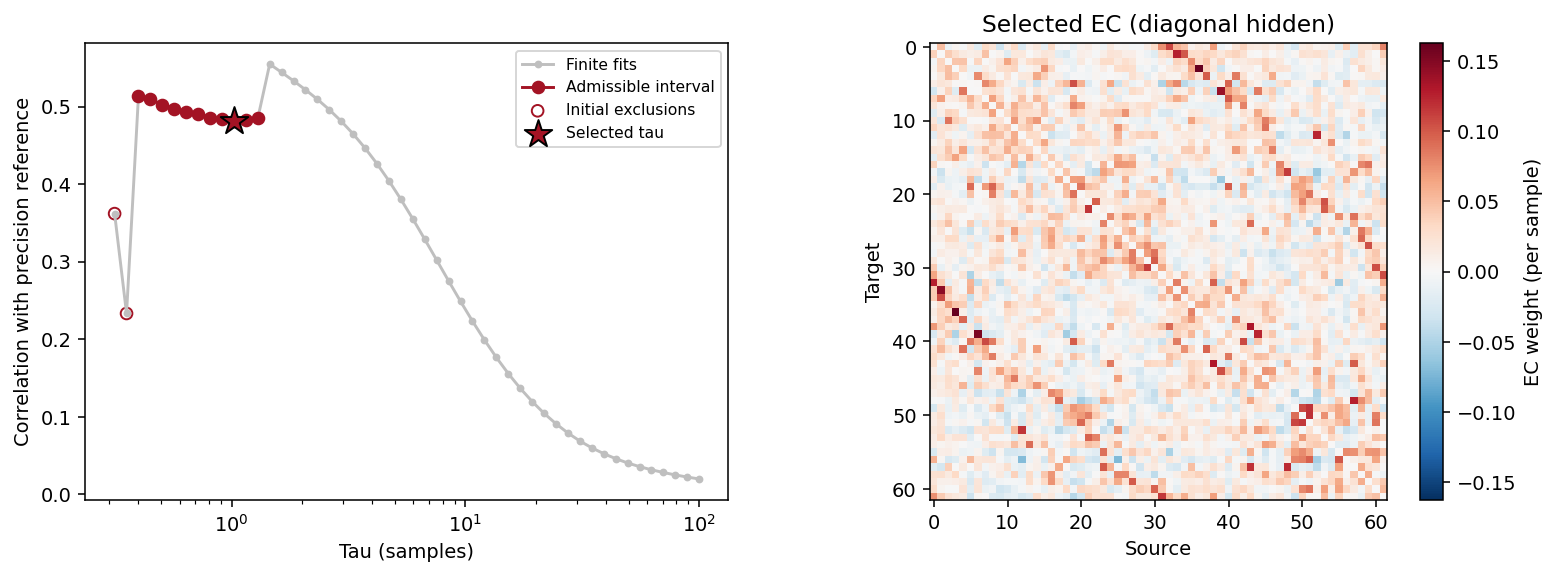

In [ ]:
# Inspect both the selection curve and the selected connectivity matrix.
fig = plot_precision_result(result)
show_figure(fig)

## 4. Compare EC across tau
Pearson correlations between all ordered off-diagonal EC entries in the retained search interval. Values are shown in each cell. Similarity of patterns does not imply equal weight magnitudes.

EC across tau: mean r = 0.9974; minimum r = 0.9891


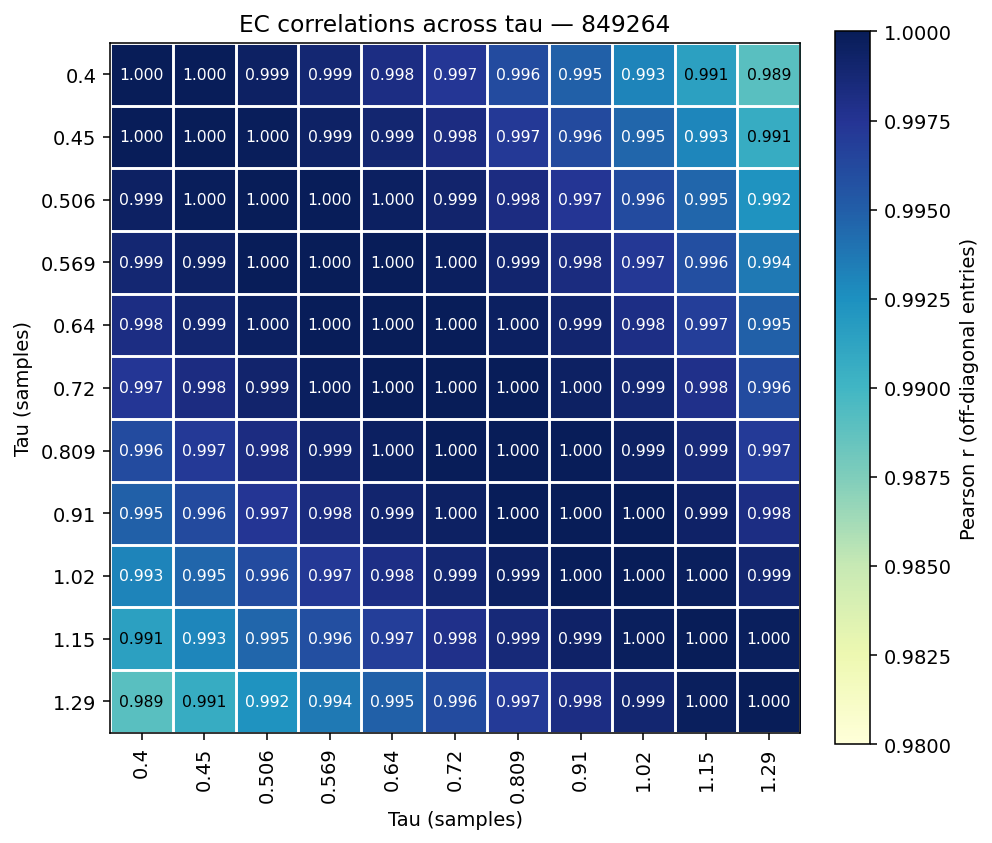

In [ ]:
# Compare the valid EC estimates across tau, excluding every diagonal.
indices = np.flatnonzero(result["search_mask"])
if len(indices) < 3:
    raise RuntimeError("Insufficient eligible EC estimates for comparison.")
ec_correlations = result['ec_correlations_all'][np.ix_(indices, indices)]
selected_taus = result["taus"][indices]
pairwise = ec_correlations[np.triu_indices(len(indices), k=1)]
print(f"EC across tau: mean r = {pairwise.mean():.4f}; minimum r = {pairwise.min():.4f}")
fig, ax = plt.subplots(figsize=(7, 6), constrained_layout=True)
im = ax.imshow(ec_correlations, cmap="YlGnBu", vmin=min(0.98, float(pairwise.min())), vmax=1, interpolation="nearest")
labels = [f"{tau:.3g}" for tau in selected_taus]
ax.set_xticks(range(len(indices)), labels, rotation=90)
ax.set_yticks(range(len(indices)), labels)
ax.set_xticks(np.arange(len(indices)+1)-0.5, minor=True)
ax.set_yticks(np.arange(len(indices)+1)-0.5, minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)
for row in range(len(indices)):
    for col in range(len(indices)):
        color = "white" if im.norm(ec_correlations[row,col]) > 0.6 else "black"
        ax.text(col, row, f"{ec_correlations[row,col]:.3f}", ha="center", va="center", color=color, fontsize=8)
ax.set(xlabel="Tau (samples)", ylabel="Tau (samples)", title=f"EC correlations across tau — {SUBJECT_ID}")
fig.colorbar(im, ax=ax, label="Pearson r (off-diagonal entries)")
show_figure(fig)
np.savez_compressed(OUTPUT_FILE.with_name(OUTPUT_FILE.stem + "_EC_correlations.npz"),
    taus=selected_taus, correlations=ec_correlations,
    subject_id=result["subject_id"], run=result["run"])
# Optional figure export:
fig.savefig(OUTPUT_FILE.with_name(OUTPUT_FILE.stem + "_EC_correlations.jpg"), dpi=300, bbox_inches="tight")


## 5. Reload the saved results
Run the setup and selection-function cells, then this cell. The selected EC, diagnostics and pairwise EC correlations are loaded directly; no fitting is needed.

Subject: 849264 Run: REST1_LR Tau: 1.023773966339585


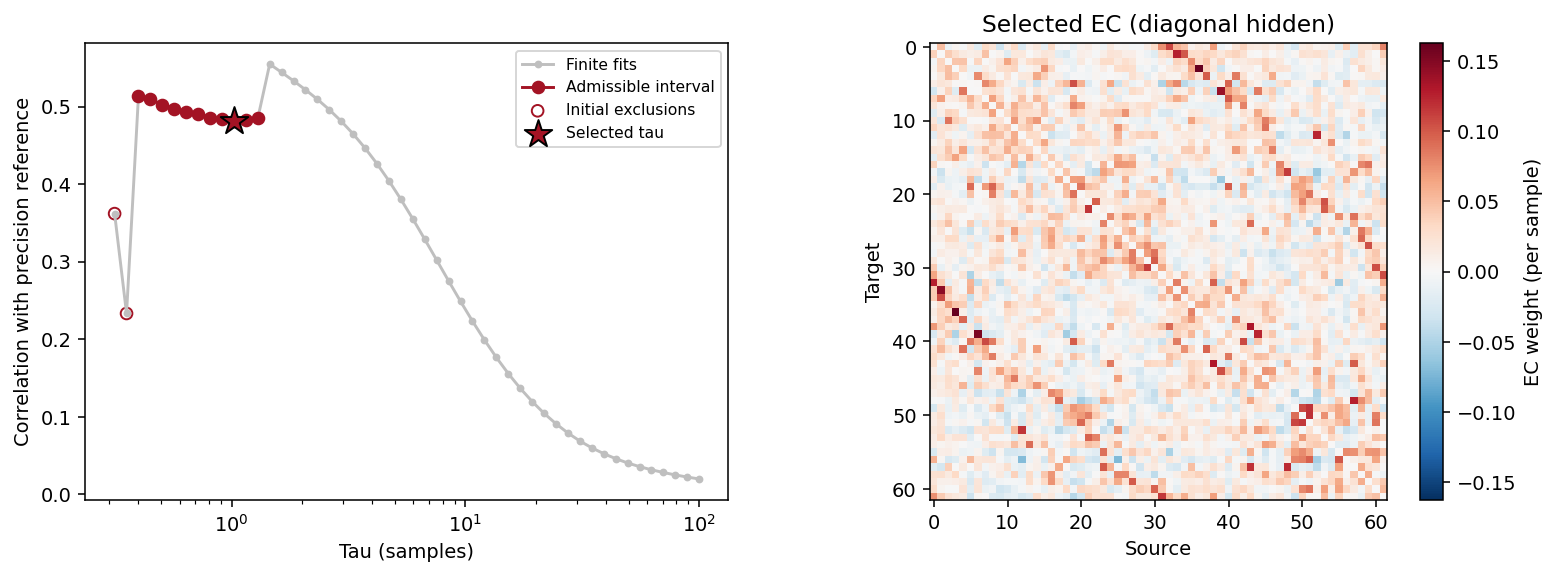

In [ ]:
with np.load(OUTPUT_FILE, allow_pickle=False) as saved:
    result = {key: saved[key] for key in saved.files}
assert str(result["subject_id"]) == SUBJECT_ID and str(result["run"]) == RUN
print("Subject:", result["subject_id"], "Run:", result["run"], "Tau:", result["tau_opt"])
fig = plot_precision_result(result)
show_figure(fig)
